In [ ]:
"""Backtest `ROUND_2/trader_6.py` with `prosperity3bt`.

The CSVs in `ROUND_2/` use comma-separated prices; the backtester expects semicolons.
This notebook stages a temp `round2/` folder in the shape `FileSystemReader` needs.

Install once: `pip install -e imc-prosperity-3-backtester` (from repo root).
"""

from __future__ import annotations

import csv
import sys
import tempfile
from importlib import reload
from pathlib import Path


def find_repo(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / "ROUND_2" / "trader_6.py").is_file() and (
            p / "imc-prosperity-3-backtester" / "prosperity3bt"
        ).is_dir():
            return p
    raise RuntimeError(
        "Could not find repo root (need ROUND_2/trader_6.py and imc-prosperity-3-backtester/)."
    )


REPO = find_repo(Path.cwd().resolve())
BT_PKG = REPO / "imc-prosperity-3-backtester"
ROUND_2 = REPO / "ROUND_2"

sys.path.insert(0, str(BT_PKG))
sys.path.insert(0, str(ROUND_2))

import prosperity3bt.data as bt_data
from prosperity3bt.file_reader import FileSystemReader
from prosperity3bt.models import TradeMatchingMode
from prosperity3bt.runner import run_backtest

import trader_6

# Must mutate LIMITS in place so runner.enforce_limits sees it (it imported the dict at load time).
bt_data.LIMITS.update(
    {
        trader_6.PEPPER: trader_6.POSITION_LIMIT,
        trader_6.OSMIUM: trader_6.POSITION_LIMIT,
    }
)


def stage_round2_csvs(round2_src: Path, staging_root: Path) -> Path:
    out = staging_root / "round2"
    out.mkdir(parents=True, exist_ok=True)
    for day in (-1, 0, 1):
        pin = round2_src / f"prices_round_2_day_{day}.csv"
        tin = round2_src / f"trades_round_2_day_{day}.csv"
        pout = out / f"prices_round_2_day_{day}.csv"
        tout = out / f"trades_round_2_day_{day}.csv"
        with pin.open(newline="", encoding="utf-8") as f_in, pout.open(
            "w", newline="", encoding="utf-8"
        ) as f_out:
            writer = csv.writer(f_out, delimiter=";")
            writer.writerows(csv.reader(f_in))
        if tin.is_file():
            tout.write_bytes(tin.read_bytes())
    return staging_root


def print_day_summary(result) -> None:
    last_ts = result.activity_logs[-1].timestamp
    lines: list[str] = []
    total = 0.0
    for row in reversed(result.activity_logs):
        if row.timestamp != last_ts:
            break
        product, pnl = row.columns[2], row.columns[-1]
        lines.append(f"  {product}: {pnl:,.0f}")
        total += pnl
    print("\n".join(reversed(lines)))
    print(f"Total P&L: {total:,.0f}")


# Filled by the backtest loop; use in the plotting cell below.
results: dict[int, object] = {}

with tempfile.TemporaryDirectory() as tmpdir:
    data_root = stage_round2_csvs(ROUND_2, Path(tmpdir))
    reader = FileSystemReader(data_root)

    for day in (-1, 0, 1):
        print(f"\n=== Round 2 day {day} ===")
        reload(trader_6)
        result = run_backtest(
            trader_6.Trader(),
            reader,
            2,
            day,
            print_output=False,
            trade_matching_mode=TradeMatchingMode.all,
            no_names=True,
            show_progress_bar=False,
        )
        print(result)
        results[day] = result
        print_day_summary(result)


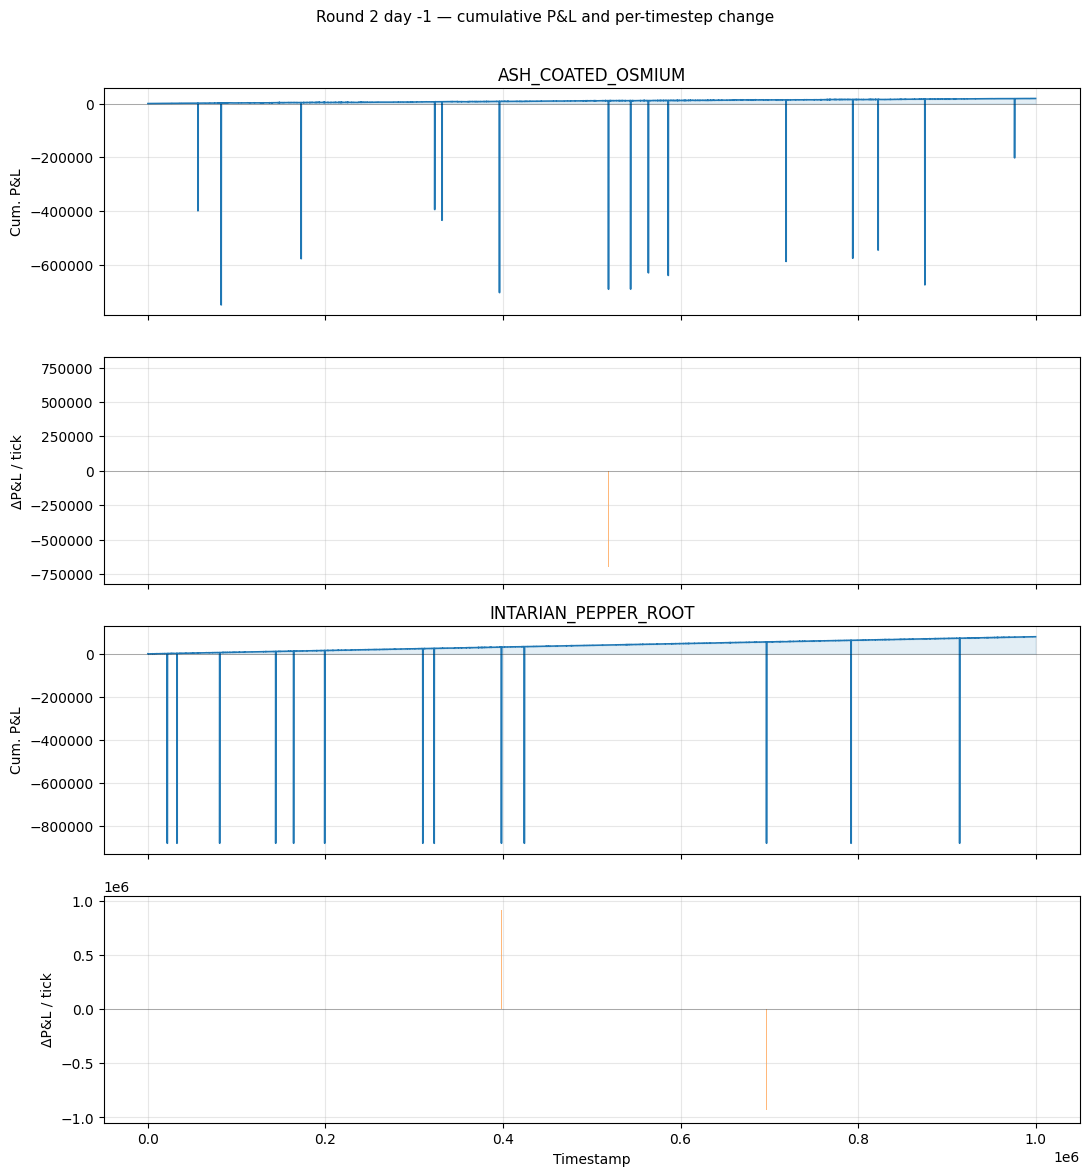

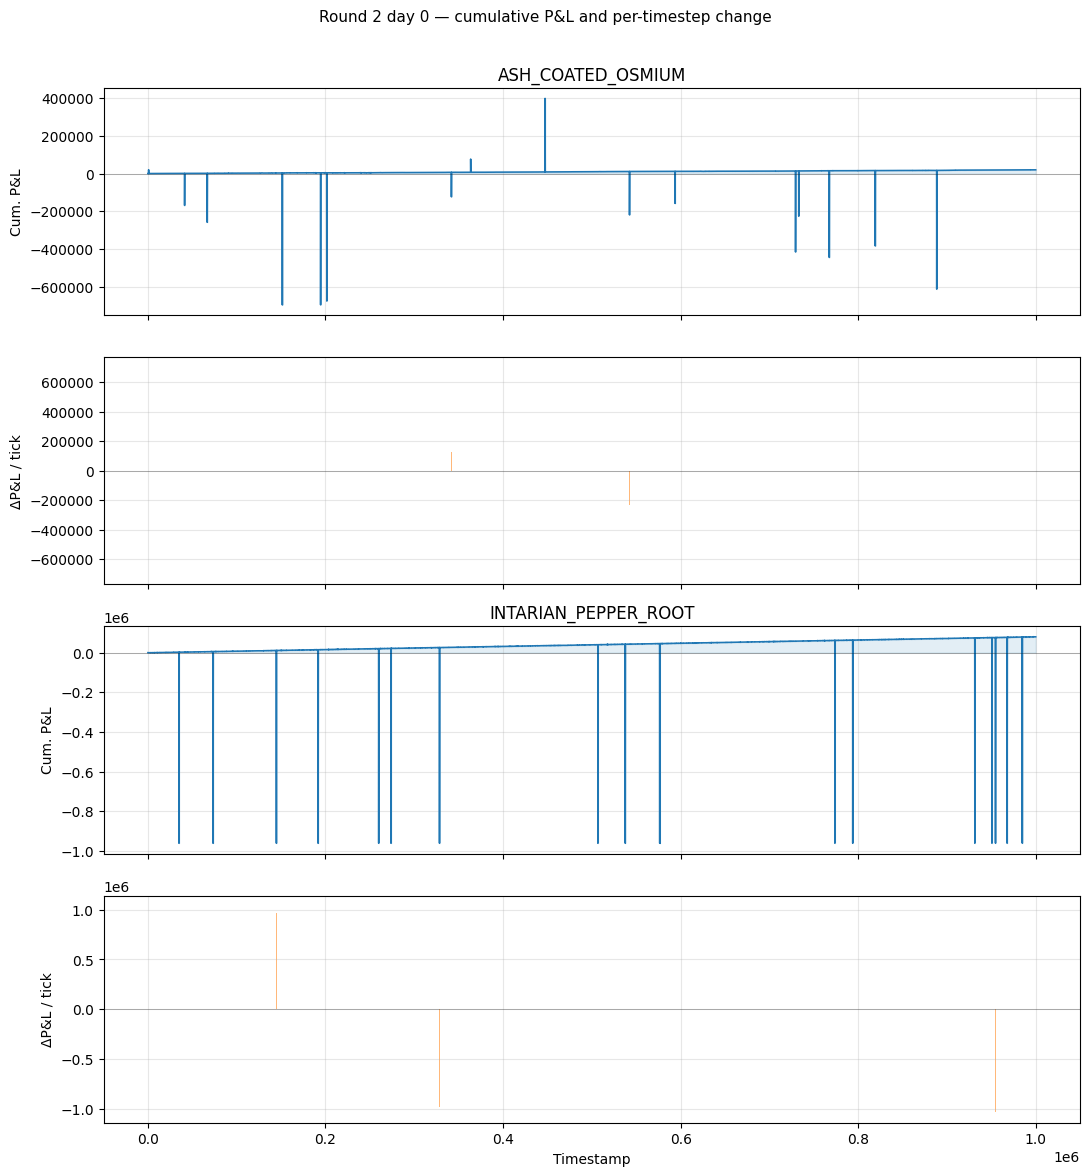

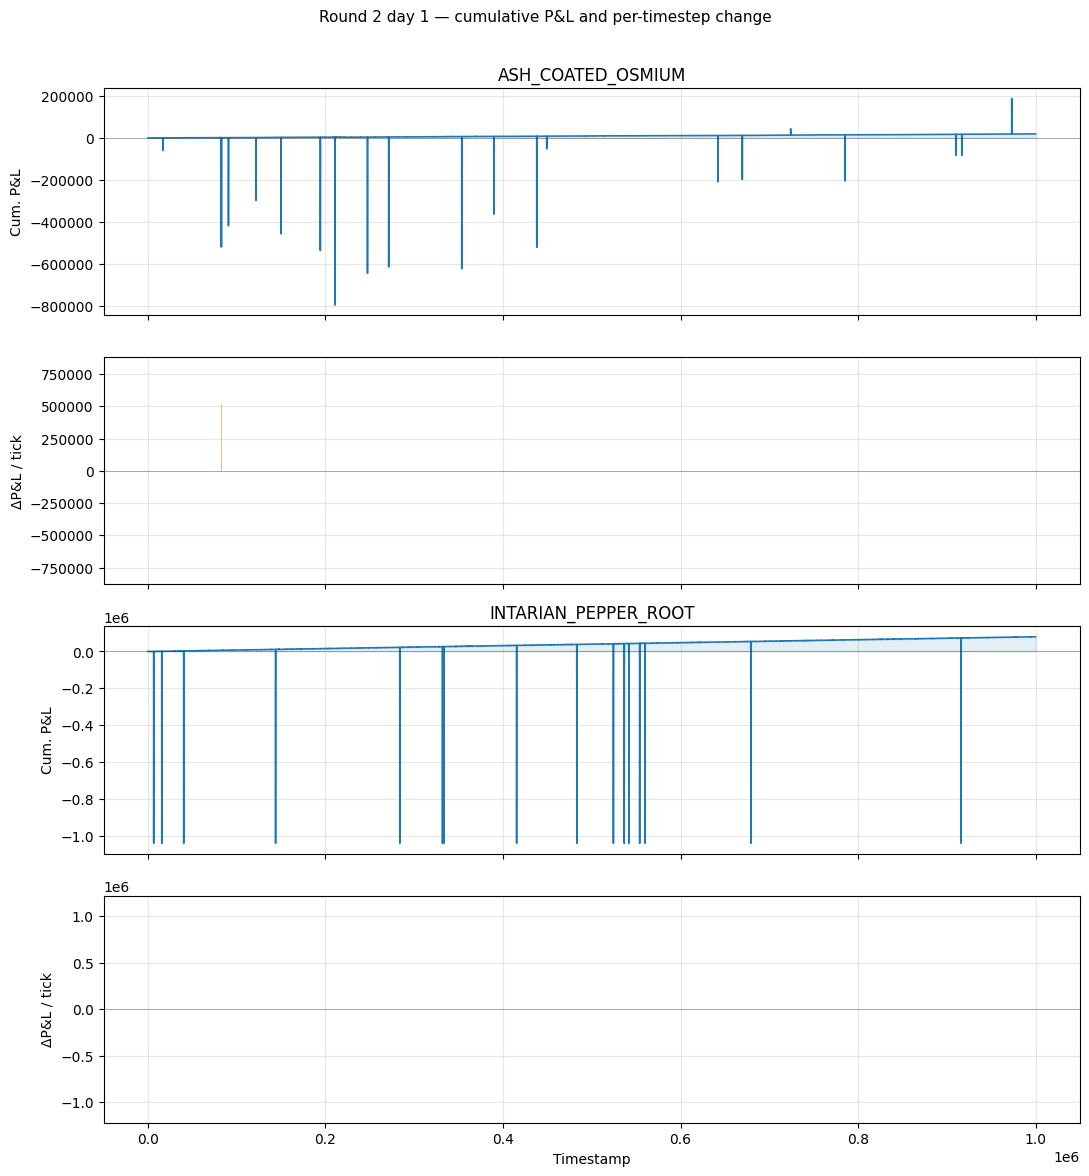

In [6]:
# Per-product P&L vs timestep: cumulative path (top) and per-tick ΔP&L (bottom) for each product.
# Requires: run the backtest cell above first (`results` dict).

%matplotlib inline

import matplotlib.pyplot as plt
from collections import defaultdict


def pnl_paths_by_product(result) -> dict[str, tuple[list[int], list[float]]]:
    """One series per product: timestamps and cumulative P&L from the activity log."""
    by_prod: dict[str, list[tuple[int, float]]] = defaultdict(list)
    for row in result.activity_logs:
        ts = int(row.columns[1])
        prod = row.columns[2]
        pnl = float(row.columns[-1])
        by_prod[prod].append((ts, pnl))
    out: dict[str, tuple[list[int], list[float]]] = {}
    for prod, pairs in by_prod.items():
        pairs.sort(key=lambda x: x[0])
        out[prod] = ([p[0] for p in pairs], [p[1] for p in pairs])
    return out


def _typical_timestep_gap(ts: list[int]) -> float:
    if len(ts) < 2:
        return 100.0
    gaps = [ts[i + 1] - ts[i] for i in range(len(ts) - 1)]
    positives = [g for g in gaps if g > 0]
    return min(positives) if positives else float(abs(ts[-1] - ts[0]) / max(len(ts) - 1, 1))


def plot_pnl_per_product(results_map: dict[int, object]) -> None:
    if not results_map:
        print("No results to plot — run the backtest cell first.")
        return

    for day in sorted(results_map.keys()):
        result = results_map[day]
        paths = pnl_paths_by_product(result)
        products = sorted(paths.keys())
        if not products:
            continue

        n = len(products)
        fig, axes = plt.subplots(n * 2, 1, figsize=(11, 2.9 * n * 2), sharex=True)
        axes = list(axes)

        for i, prod in enumerate(products):
            ts, pnl = paths[prod]
            ax_c = axes[2 * i]
            ax_d = axes[2 * i + 1]

            ax_c.plot(ts, pnl, color="C0", lw=1.15)
            ax_c.fill_between(ts, pnl, alpha=0.12, color="C0")
            ax_c.axhline(0.0, color="black", lw=0.55, alpha=0.35)
            ax_c.set_ylabel("Cum. P&L")
            ax_c.set_title(prod)
            ax_c.grid(True, alpha=0.3)

            deltas = [pnl[j] - pnl[j - 1] for j in range(1, len(pnl))]
            dts = ts[1:]
            w = _typical_timestep_gap(ts) * 0.45
            ax_d.bar(dts, deltas, width=w, alpha=0.55, color="C1")
            ax_d.axhline(0.0, color="black", lw=0.55, alpha=0.35)
            ax_d.set_ylabel("ΔP&L / tick")
            ax_d.grid(True, alpha=0.3)

        axes[-1].set_xlabel("Timestamp")
        fig.suptitle(
            f"Round {result.round_num} day {day} — cumulative P&L and per-timestep change",
            fontsize=11,
            y=1.01,
        )
        fig.tight_layout()
        plt.show()


plot_pnl_per_product(results)